# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: NOMBRE DEL GRUPO

# Integrantes
* integrante
* integrante

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



### Ejercicio 3 - Calibración con puntos coplanares

> ¿Qué rango debe tener $Q \in \mathbb{R}^{2n\times 9}$ para asegurar
> una solución única de $H$ a menos de un factor de escala?

**Demostración:**

Por la ecuación (11) del TP: $Q\mathbf{h} = \mathbf{0}$, con $Q$ de $2n \times 9$
y $\mathbf{h} = \vec{H}$ vectorizado de $9 \times 1$, donde $H$ es una homografía
válida de rango 3.

Por como está construido $\mathbf{h}$, es un vector no nulo
que pertenece al núcleo de $Q$, es decir $\mathbf{h} \in \mathcal{N}(Q)$ y
$\mathbf{h} \neq \mathbf{0}$.

Por lo tanto $\mathbf{h}$ es una solución no trivial del espacio nulo de $Q$.

Para que $\mathbf{h}$ sea una solución única a menos de un factor de escala, el conjunto de soluciones de $Q\mathbf{h}=0$ debe ser una recta que pasa por el origen: $\{c\,\mathbf{h}: c \in \mathbb{R}, c\neq 0\}$, es decir, $\dim\mathcal{N}(Q)=1$.

Por el teorema del rango y la nulidad, $\operatorname{rango}(Q) + \dim \mathcal{N}(Q) = 9$ 
($Q$ tiene 9 columnas). Dado que $\dim \mathcal{N}(Q) = 1$, entonces $$\operatorname{rango}(Q) = 9 - 1 = \boxed{8}$$

Como $\operatorname{rango}(Q) \le \min(2n,\,9)$, para alcanzar rango 8 se necesita
$2n \geq 8$, es decir, **al menos $n = 4$ puntos** por vista, y basta que exista un grupo de 4 en posición general (ninguna terna de esos 4 colineal). El tablero de 77 esquinas lo cumple de sobra.

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


In [1]:
import os
import importlib
import numpy as np
import alc
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import pandas as pd

importlib.reload(alc)
np.set_printoptions(precision=4, suppress=True)

# rutas (notebook en la raíz del repo)
PATH_CORNERS = os.path.join("calib", "coplanar", "detected_corners.txt")
N_IMG, N_PTS = 10, 77

In [2]:
# proyecciones detectadas: 1 fila por imagen, esquinas intercaladas (u,v)
detected = np.loadtxt(PATH_CORNERS)              # (10, 154)
print("detected:", detected.shape)               # sanity del formato

# puntos del tablero: analíticos, fila-mayor (X=30i, Y=30j, Z=0) en mm
n = np.arange(N_PTS)
objPts = np.zeros((N_PTS, 3))
objPts[:, 0] = 30.0 * (n % 11)
objPts[:, 1] = 30.0 * (n // 11)
objPts[:, 2] = 0.0 # plano W=0 del tablero
print("objPts[0], objPts[11], objPts[76]:", objPts[0], objPts[11], objPts[76])

X, Y = objPts[:, 0], objPts[:, 1]        # (usadas por el QA de reproyección y los plots

detected: (10, 154)
objPts[0], objPts[11], objPts[76]: [0. 0. 0.] [ 0. 30.  0.] [300. 180.   0.]


### Calibración (Zhang 2000, caso coplanar)

Cada imagen aporta la homografía $H_j$ (solución de mínimos cuadrados
homogéneos, ec. 8) y las restricciones

$$ \mathbf{c}_1^{j\top} B\, \mathbf{c}_2^j = 0, \qquad
   \mathbf{c}_1^{j\top} B\, \mathbf{c}_1^j \;=\; \mathbf{c}_2^{j\top} B\, \mathbf{c}_2^j $$

con $B = K^{-\top}K^{-1}$ simétrica ⇒ 6 incógnitas $\mathbf b=(B_{11},B_{12},B_{22},B_{13},B_{23},B_{33})^\top$.
Armando $A\in\mathbb{R}^{2N\times 6}$ y tomando el **vector nulo** de $A$ (norma 1)
obtenemos $\mathbf b$; el signo se elige de modo que $B$ sea definida positiva,
y $K = (L^\top)^{-1}$ con $B = LL^\top$ (Cholesky), normalizada con $K_{33}=1$.

>b) Obtener la matriz $\mathbf{K}$

In [3]:
# 1. Homografía por imagen: DLT coplanar (ec. 11 + ec. 8)
Hlst = []
for k in range(N_IMG):
    imgPts = detected[k].reshape(N_PTS, 2)
    Q  = alc.obtenerQ2d(imgPts, objPts)            # (154, 9)
    H  = alc.resolverDLT2D(Q)                      # (3, 3), ‖h‖=1 
    Hlst.append(H)

# 2. Matriz A de restricciones de Zhang (ec. 13): 2 filas por vista
A = alc.armarA(Hlst)                               # (20, 6)

# 3. K: núcleo de A → b → B def. positiva → Cholesky → K (K33=1)
K = alc.calcularMatrizK2D(A)
print("K:\n", K)

K:
 [[742.3299  -0.6789 520.4803]
 [  0.     753.564  299.2673]
 [  0.       0.       1.    ]]


>c) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

In [4]:
# Pose (R1, t1) de la cámara respecto del tablero en la captura Im_R_1.png;
# t viaja en mm (λ = 1/‖K⁻¹c₁‖ re-escala la normalización arbitraria del
# vector nulo de la SVD a las unidades de las esquinas del tablero).
# El signo de H es arbitrario: si el DLT devuelve −H, la pose sale como la
# variante alternativa válida (R' = R·diag(−1,−1,1)) — ver markdown de abajo.
Rj1, tj1 = alc.obtenerPose2D(Hlst[0], K)
Rj10, tj10 = alc.obtenerPose2D(Hlst[9], K)
print(f'======== Pose Im_R_1 ======\n Rj1 \n{Rj1}\n tj1\n{tj1}')
print(f'======== Pose Im_R_10 ======\n Rj10 \n{Rj10}\n tj10\n{tj10}')



======== Pose Im_R_1 ======
 Rj1 
[[-0.9995  0.013  -0.0276]
 [-0.0121 -0.9994  0.0078]
 [-0.0275  0.0082  0.9991]]
 tj1
[ 109.2896  141.8554 -548.2162]
======== Pose Im_R_10 ======
 Rj10 
[[-0.9974 -0.0682 -0.025 ]
 [ 0.0632 -0.9856  0.157 ]
 [-0.0353  0.155   0.9874]]
 tj10
[  96.5027  154.4873 -538.9271]


### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

En este ítem vamos a usar los puntos que estan en world_img_pts, que son 5 con su posición en la calle y sus pixeles en 4 vistas diferentes.
Cuando miramos los puntos notamos el primer inconveniente: No estan en el mismo plano. Hay 3 puntos que estan a Z=0.1m ya que están marcados sobre la vereda. Para poder usar Zhang necesitamos que estén en el mismo plano, así que por el momento vamos a asumir que esos 3 puntos estan en 0, ya que es una corrección pequeña comparado con las distancias que vamos a analizar luego. Sin embargo tenemos que tenerlo en cuenta más adelante por si aparece algo extraño en los resultados.

In [5]:
#OBTENEMOS K

def error_reproyeccion(H, mundo, pixeles):
    """
    Mide qué tan lejos caen los puntos proyectados con H de los marcados en la imagen.

    Parámetros
    ----------
    H : ndarray (3, 3) — homografía plano → imagen.
    mundo : ndarray (n, 3) — puntos (X, Y, Z) en metros, sobre el plano (Z = 0).
    pixeles : ndarray (n, 2) — puntos (u, v) marcados en la imagen.

    Devuelve
    --------
    promedio : float — distancia promedio en píxeles.
    maximo : float — distancia máxima en píxeles.
    """
    # Proyecto los puntos del mundo en coordenadas homogéneas y divido por la tercera fila
    P = np.vstack((mundo[:, 0], mundo[:, 1], np.ones(mundo.shape[0])))
    proy = alc.multiplicar(H, P)
    u = proy[0] / proy[2]
    v = proy[1] / proy[2]

    # Distancia de cada punto proyectado a su marca
    error = np.sqrt((u - pixeles[:, 0])**2 + (v - pixeles[:, 1])**2)
    return np.mean(error), np.max(error)

#Me traigo los puntos del csv
CSV_Path = os.path.join("salguero", "world_img_pts.csv")
datos = pd.read_csv(CSV_Path, sep=";")
#print(datos)

#Puntos del mundo: desprecio los 0.1 m del cordón y dejo todos en el plano Z = 0
mundo5 = np.zeros((datos.shape[0], 3))
mundo5[:, 0] = datos["X"]
mundo5[:, 1] = datos["Y"]

#Una homografía por vista
N_VISTAS = 4
H_vistas = []
for k in range(N_VISTAS):
    pixeles_k = np.array(datos[[f"u_{k}", f"v_{k}"]], dtype=float)
    Q_k = alc.obtenerQ2d(pixeles_k, mundo5)
    H_k = alc.resolverDLT2D(Q_k)
    H_vistas.append(H_k)

    prom, maxi = error_reproyeccion(H_k, mundo5, pixeles_k)
    print(f"Vista {k}: error promedio {prom:.2f} px, máximo {maxi:.2f} px")

#Zhang: armo A con las 4 homografías y saco K
A_csv = alc.armarA(H_vistas)
K_csv = alc.calcularMatrizK2D(A_csv)
print("K con Zhang (csv, Z = 0):\n", K_csv)

Vista 0: error promedio 5.03 px, máximo 9.97 px
Vista 1: error promedio 6.64 px, máximo 12.97 px
Vista 2: error promedio 5.71 px, máximo 10.35 px
Vista 3: error promedio 5.53 px, máximo 10.40 px
K con Zhang (csv, Z = 0):
 [[2782.7801 1355.3658  289.0903]
 [   0.      213.0557  195.627 ]
 [   0.        0.        1.    ]]


ANALISIS DE LA K OBTENIDA:
Primero que nada, las H por vista estan, dentro de todo, bastante bien, entre 5 a 6 pixeles de error en promedio (aunque en el peor caso hay entre 10 a 13 pixeles de error).

El problema grave está en la K:
au = 2783 y av = 213, mas de 13 veces distinto. y = 1355 cuando deberia ser casi 0. Y el centro (289,195) cae casi en una esquina cuando debería estar cerca del medio de la imagen (800,600).

Hay algo que está mal.

POSIBLES CAUSAS:

Despues de bastantes vueltas y análisis, encontramos 4 posibles causas para estos valores de K absurdos:
- El cordón: Al despreciar esos 0,1m para armar el plano introdujimos errores en la k. Sin embargo, este pequeño ajuste no explica por si solo los valores tan desbalanceados de K.
- Pocos puntos: Para calcular cada H se necesitan al menos 4 puntos, y tenemos 5. Alcanza para calcularlas, sin embargo estamos tan cerca del mínimo necesario que no tenemos redundancia. Cualquier error a la hora de marcar un punto (ya sea en elegir el pixel o dar la coordenada en el mundo real) puede introducir mucho ruido, que si tuvieramos mas puntos se mitigaria.
- Vistas parecidas: El método de Zhang se beneficia de tener vistas distintas entre sí, sin embargo las 4 vistas de la cámara son bastante similares en altura y posición, haciendo menos estables los datos de la k.
- Coordenadas inconsistentes: Esto lo notamos al utilizar los 51 puntos para el item b y c, parecería que 5 de los puntos en ese archivo y en el que usamos en este item (el a) son los mismos. Esto lo podemos ver porque la imagen de la señora de rojo cruzando la calle (img_10_18_47_351.jpg) está en los dos datasets. Buscando los pixeles se puede ver que hay 5 que parecen corresponder con los de world_img_pts (los pixeles seleccionados están entre 0 y 2 pixeles de diferencia, una diferencia consistente con el error de marcarlos a mano en una imagen). Sin embargo las coordenadas del mundo son distintas:


| Punto csv | Punto archivo de 51 | Distancia en píxeles | Mundo csv (X, Y, Z) | Mundo archivo de 51 (X, Y, Z) | Diferencia |
|---|---|---|---|---|---|
| 6 | 2 | 1.0 px | (-4, 3, 0) | (-4, 3, 0) | ninguna |
| 36 | 32 | 2.0 px | (4, 0, 0) | (4.5, 0, 0) | X: 0.5 m |
| 40 | 46 | 2.2 px | (6.5, 3, 0.1) | (7.2, 2.8, 0) | X: 0.7 m, Y: 0.2 m, Z: 0.1 m |
| 41 | 47 | 0.0 px | (-5, 14, 0.1) | (-6, 14, 0) | X: 1 m, Z: 0.1 m |
| 42 | 48 | 0.0 px | (-5, 76, 0.1) | (-6, 76, 0) | X: 1 m, Z: 0.1 m |

En un principio pensamos que arreglando esto podíamos llegar a tener una K mejor, sin embargo,  a pesar de mejorar H y un poco el K, los valores seguían estando mal:

In [6]:
#Corrección A: mismos píxeles del csv, pero con las coordenadas del archivo de 51
#(emparejamiento de la comparación de arriba: csv 6, 36, 40, 41, 42 -> 2, 32, 46, 47, 48)
mundo5_gs = np.array([[-4.0,  3.0, 0],
                      [ 4.5,  0.0, 0],
                      [ 7.2,  2.8, 0],
                      [-6.0, 14.0, 0],
                      [-6.0, 76.0, 0]])

H_vistas_gs = []
for k in range(N_VISTAS):
    pixeles_k = np.array(datos[[f"u_{k}", f"v_{k}"]], dtype=float)
    Q_k = alc.obtenerQ2d(pixeles_k, mundo5_gs)
    H_k = alc.resolverDLT2D(Q_k)
    H_vistas_gs.append(H_k)

    prom, maxi = error_reproyeccion(H_k, mundo5_gs, pixeles_k)
    print(f"Vista {k}: error promedio {prom:.2f} px, máximo {maxi:.2f} px")

A_gs = alc.armarA(H_vistas_gs)
K_gs = alc.calcularMatrizK2D(A_gs)
print("K con Zhang (píxeles del csv, coordenadas del archivo de 51):\n", K_gs)

Vista 0: error promedio 2.26 px, máximo 4.19 px
Vista 1: error promedio 2.83 px, máximo 5.51 px
Vista 2: error promedio 1.72 px, máximo 3.13 px
Vista 3: error promedio 1.98 px, máximo 3.68 px
K con Zhang (píxeles del csv, coordenadas del archivo de 51):
 [[2027.0313  452.4239  764.3329]
 [   0.      133.8025  224.7427]
 [   0.        0.        1.    ]]


H mejoró bastante y hay menos error promedio y maximo. Sin embargo la K sigue estando mal (aunque un poco mejor). Osea que agarrando los nuevos puntos no vamos a solucionar nuestro problema. Como el ejercicio dice que debemos usar los de world_img_pts nos quedamos con esos para seguir, pero valía la pena notar que quizás los datos estan mal de base.

La nueva corrección que podríamos hacer es forzar algunos valores de la K, que ya sabemos mas o menos cuales deberían ser (aunque es una suposición que hay que justificar). Por ejemplo:
- y = 0: Porque los ejes del sensor son perpendiculares.
- au = av = f: Porque los pixeles son cuadrados.
- Centro (u0,v0) = (800, 600): Porque es el medio de la imagen.

De esta manera K queda [[f, 0, 800], [0, f, 600], [0, 0, 1]] y solo tendríamos que encontrar f.


In [7]:
#Cargo los 51 puntos: los uso para verificar f acá y en los ítems b y c
#Me traigo los puntos y los guardo en una matriz
GS_Path = os.path.join("salguero", "gs_10_09_point_correspondences_v5.txt")
pts = np.loadtxt(GS_Path)
print(pts.shape)

#Separo en los puntos de los objetos y de la imagen, las guardo en el formato necesario para las funciones
objPts = alc.transponer(pts[1:4])
imgPts = alc.transponer(pts[4:6])
print(objPts.shape, imgPts.shape)

#Busco Q y H
Q = alc.obtenerQ2d(imgPts, objPts)
H = alc.resolverDLT2D(Q)
print(Q.shape, H.shape)

(6, 51)
(51, 3) (51, 2)
(102, 9) (3, 3)


In [8]:
def que_tan_rotacion(H, f):
    """
    Mide qué tan lejos están r1 y r2 de ser columnas de una rotación,
    si la cámara tuviera la K simplificada con foco f.

    Parámetros
    ----------
    H : ndarray (3, 3) — homografía plano → imagen de una vista.
    f : float — foco en píxeles a probar.

    Devuelve
    --------
    coseno : float — coseno del ángulo entre r1 y r2 (0 si son perpendiculares).
    cociente : float — largo de r1 dividido largo de r2 (1 si miden lo mismo).
    """
    K = np.array([[f, 0, 800],
                  [0, f, 600],
                  [0, 0, 1]])
    RT = alc.multiplicar(alc.inversa(K), H)   # columnas: r1, r2, t (a menos de escala)
    r1 = RT[:, 0]
    r2 = RT[:, 1]
    largo1 = np.sqrt(np.sum(r1**2))
    largo2 = np.sqrt(np.sum(r2**2))
    coseno = np.sum(r1 * r2) / (largo1 * largo2)
    return coseno, largo1 / largo2

def mejor_f(H_lista, candidatos):
    """
    Busca, entre los candidatos, la f con la que r1 y r2 quedan más
    parecidos a una rotación, sumando el error de todas las vistas.

    Parámetros
    ----------
    H_lista : lista de ndarray (3, 3) — una homografía por vista.
    candidatos : ndarray — valores de f a probar.

    Devuelve
    --------
    mejor : float — la f con menor error.
    error_mejor : float — el error de esa f.
    """
    mejor = candidatos[0]
    error_mejor = None
    for f in candidatos:
        error = 0
        for H in H_lista:
            coseno, cociente = que_tan_rotacion(H, f)
            error = error + coseno**2 + (cociente - 1)**2 #Nos sirve este tipo de error porque coseno y cociente no dependen de la escala de H. Van ^2 para ignorar el signo.
        if error_mejor is None or error < error_mejor:
            mejor = f
            error_mejor = error
    return mejor, error_mejor

#Pruebo f entre 1000 y 5000 píxeles, de a 10
candidatos = np.arange(1000, 5001, 10)

f_csv, e_csv = mejor_f(H_vistas, candidatos)
print(f"Con el csv: f = {f_csv}, error = {e_csv:.4f}")
for k in range(N_VISTAS):
    coseno, cociente = que_tan_rotacion(H_vistas[k], f_csv)
    print(f"   vista {k}: coseno {coseno:.3f}, cociente {cociente:.3f}")

f_gs, e_gs = mejor_f(H_vistas_gs, candidatos)
print(f"Con las coordenadas corregidas: f = {f_gs}, error = {e_gs:.4f}")
for k in range(N_VISTAS):
    coseno, cociente = que_tan_rotacion(H_vistas_gs[k], f_gs)
    print(f"   vista {k}: coseno {coseno:.3f}, cociente {cociente:.3f}")

f_51, e_51 = mejor_f([H], candidatos)
print(f"Con los 51 puntos: f = {f_51}, error = {e_51:.4f}")
coseno, cociente = que_tan_rotacion(H, f_51)
print(f"   coseno {coseno:.3f}, cociente {cociente:.3f}")

Con el csv: f = 3160, error = 0.2013
   vista 0: coseno -0.274, cociente 0.983
   vista 1: coseno -0.079, cociente 1.258
   vista 2: coseno -0.140, cociente 1.019
   vista 3: coseno -0.176, cociente 1.043
Con las coordenadas corregidas: f = 2170, error = 0.0619
   vista 0: coseno -0.134, cociente 0.908
   vista 1: coseno 0.049, cociente 1.168
   vista 2: coseno 0.027, cociente 0.948
   vista 3: coseno -0.003, cociente 0.963
Con los 51 puntos: f = 1990, error = 0.0002
   coseno -0.013, cociente 1.006


COMO ENCONTRAMOS F?

Con la K simplificada solo faltaba encontrar f. Para elegirlo usamos una propiedad de la pose: Si K es correcta, entonces cuando despejemos y hagamos K^-1 * H las dos primeras columnas (r1 y r2) son de rotación, osea que deberían ser perpendiculares (coseno 0) y medir lo mismo. Probamos con f entre 1000 y 5000 pixeles, de 10 a 10 y para cada una vemos el error, sumado en todas las vistas. Finalmente nos quedamos con la f que tenga menos error.

Lo hacemos con 3 conjuntos de homografías:
[los grados se pueden despejar del coseno, pero no lo agregamos porque se usan funciones no permitidas, se puede hacer con una calculadora cientifica igual]

1) Con el csv (4 vistas): f = 3160, error 0.20. Incluso con la mejor f, r1 y r2 quedan mal (angulos de hasta 106 grados, y tienen tamaños distintos). Ninguna f arregló la camara, así que el probelma sale de los datos (por eso nos terminamos fijando en los puntos con las coordenadas corregidas del archivo de 51 pts).

2) Con las coordenadas corregidas (4 vistas): f = 2170, error 0,06. Mejoró bastante, los angulos de la camara van entre 87 grados a 98 aprox, aunque sigue estando un poco mal.

3) Con los 51 puntos (1 sola vista): f = 1990, error 0,0002. Aca dió casi perfecto, unos 90.7 grados y cociente de 1,006, pracicamente una rotación perfecta.

ELECCION FINAL: 
Finalmente elegimos la f = 1990, sacada de los 51 puntos. Esto porque son muchos mas puntos, bien repartidos y es la única que hace que la pose cumpla con las condiciones de una rotación.

RIESGOS:
- Supusimos el centro en (800,600). Si el centro llegara a estar corrido entonces f absorbe parte del error.
- Supusimos pixeles cuadrados y y=0. 
- No se tiene en cuenta si la camara tiene alguna distorsion.
- Lo mas importante: la f final la sacamos de los 51 puntos, no del csv que pide el enunciado. Creemos que esta es la decisión correcta, usando el csv para mostrar el problema y comparar, quedandonos con la f que da una camara coherente.


In [9]:
#k utilizada a partir de ahora:
f = 1990
K_calle = np.array([[f, 0, 800],
                    [0, f, 600],
                    [0, 0, 1]])

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

Bien, una vez que sabemos los valores intrínsecos de la cámara, podemos reconstruir la pose despejando y resolviendo la ecuacion de k^-1*H. Después podemos graficar los puntos marcados de los pixeles y marcar los pixeles esperados a partir de las coordenadas del mundo real según nuestro calculo de la pose de la cámara, compararlos y ver que tanto error tienen.

In [10]:
# ⚠️ TEMPORAL — BORRAR cuando entre el arreglo de obtenerPose2D (PR #20).
# Hace lo que va a hacer el arreglo de Fran: elige el signo físico de la pose
# y lleva R a la rotación más cercana. Después, reemplazar cada
# obtenerPose2D_temporal(...) por alc.obtenerPose2D(...) y borrar esta celda.
def obtenerPose2D_temporal(H, K):
    """
    TEMPORAL: pose de la cámara con el signo y R corregidos.

    Parámetros
    ----------
    H : ndarray (3, 3) — homografía plano → imagen.
    K : ndarray (3, 3) — matriz intrínseca.

    Devuelve
    --------
    R : ndarray (3, 3) — rotación (R^T R = identidad).
    t : ndarray (3,) — traslación, con t_z > 0.
    """
    R, t = alc.obtenerPose2D(H, K)

    # Signo: el origen del mundo se ve en la foto, así que está delante de la cámara (t_z > 0).
    # Si no, la pose es la espejada: se dan vuelta r1, r2 y t (r3 = r1 x r2 queda igual).
    if t[2] < 0:
        R[:, 0] = -R[:, 0]
        R[:, 1] = -R[:, 1]
        t = -t

    # Rotación más cercana: R = U S V^T  ->  R = U V^T
    U, S, Vt = alc.svd(R)
    R = alc.multiplicar(U, Vt)
    return R, t

In [11]:
#Comparo la pose con las 3 K candidatas
K_f_csv = np.array([[f_csv, 0, 800],
                    [0, f_csv, 600],
                    [0, 0, 1]])
candidatas = [("Zhang con el csv", K_csv),
              ("simplificada, f del csv", K_f_csv),
              ("simplificada, f de los 51 puntos", K_calle)]

for nombre, K in candidatas:
    R, t = obtenerPose2D_temporal(H, K)
    C = -alc.multiplicar(alc.transponer(R), t.reshape(3, 1)).reshape(3)
    M = alc.multiplicar(K, np.hstack((R[:, :2], t.reshape(3, 1))))   # cámara armada: K [r1 r2 t]
    prom, maxi = error_reproyeccion(M, objPts, imgPts)
    print(f"K {nombre}:")
    print(f"   cámara en (X, Y, Z) = ({C[0]:.1f}, {C[1]:.1f}, {C[2]:.1f}) m")
    print(f"   error en reproyección: promedio {prom:.1f} px, máximo {maxi:.1f} px")

K Zhang con el csv:
   cámara en (X, Y, Z) = (27.6, -23.5, 52.5) m
   error en reproyección: promedio 48.3 px, máximo 248.4 px
K simplificada, f del csv:
   cámara en (X, Y, Z) = (8.6, -34.7, 3.7) m
   error en reproyección: promedio 64.5 px, máximo 375.8 px
K simplificada, f de los 51 puntos:
   cámara en (X, Y, Z) = (6.7, -21.9, 3.7) m
   error en reproyección: promedio 7.4 px, máximo 20.3 px


ANALISIS:
Usando las 3 K distintas que calculamos antes podemos ver cuál ellas da una camara coherente:
- K Zhang con el csv: Da cualquier cosa, supuestamente está a 52,5 mts de altura (osea estaría como en el piso nro 15 de un edificio). Completamente absurdo mirando la perspectiva. Esto nos reafirma que la K calculada "así nomas" tiene errores graves.
- K simplificada con f = 3160(la mejor del csv): La altura es muy coherente, unos 3.7 mts de altura respecto al piso, lo que indicaría que está sobre un poste o semáforo. Sin embargo está a unos 34,7mts antes de la senda, que parece un poco lejos, pero podría ser real si la camara tuviera mucho zoom.
- K simplificada con f = 1990(k_calle): Esta es la que calculamos a partir de los 51 puntos. Está tambien a 3.7 mts de altura, pero se encuentra a 21.9mts de distancia de la senda, cosa que es bastante mas plausible. 

CON CUAL NOS QUEDAMOS?

La primera queda completamente descartada, está en cualquier lado y el error de reproyección promedio son de unos 48 pixeles y en el peor lugar casi de 250 pixeles.

Entre la 2da y 3ra, si solo miramos la pose de la cámara, no queda tan claro cual es la correcta. Pero si vemos el error en la reproyección, vemos que la ultima tiene mucho menos error: promedio 7.4 pixeles (vs 64) y maximo 20 pixeles (vs 375). Osea que la segunda arroja un MONTON de error. Vamos a elegir la última, K simplificada con f = 1990, para la reproyección final.

R:
 [[ 0.9885  0.1512  0.002 ]
 [ 0.033  -0.2027 -0.9787]
 [-0.1476  0.9675 -0.2053]]
t: [-3.2986 -1.0239 22.9331]
t_z = 22.933074611683395 (tiene que ser positivo)
R^T R =
 [[ 1.  0.  0.]
 [ 0.  1. -0.]
 [ 0. -0.  1.]]
Cámara en el mundo (X, Y, Z): [  6.6793 -21.8963   3.7138]
Error de reproyección: promedio 7.35 px, máximo 20.33 px


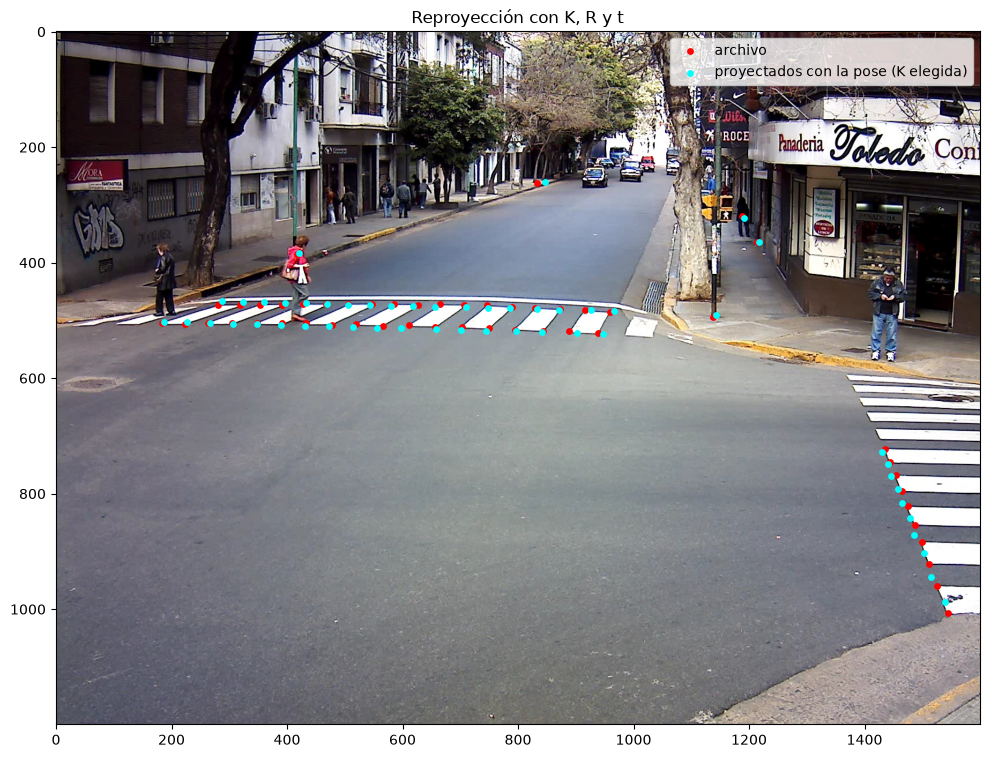

In [12]:
#Pose de la cámara con la K elegida
Rj, tj = obtenerPose2D_temporal(H, K_calle)
print("R:\n", Rj)
print("t:", tj)

#Chequeos: origen delante de la cámara y R rotación
print("t_z =", tj[2], "(tiene que ser positivo)")
print("R^T R =\n", alc.multiplicar(alc.transponer(Rj), Rj))

#Dónde está la cámara en el mundo: C = -R^T t
C = -alc.multiplicar(alc.transponer(Rj), tj.reshape(3, 1))
print("Cámara en el mundo (X, Y, Z):", C.reshape(3))

#Puntos del mundo en coordenadas homogéneas (X, Y, 1) y la imagen donde se marcaron
P = np.vstack((objPts[:, 0], objPts[:, 1], np.ones(objPts.shape[0])))
img = mpimg.imread(os.path.join("salguero", "img_10_18_47_351.jpg"))

#Reproyección con la cámara armada: K [r1 r2 t]
M = alc.multiplicar(K_calle, np.hstack((Rj[:, :2], tj.reshape(3, 1))))
proy_pose = alc.multiplicar(M, P)
u_pose = proy_pose[0] / proy_pose[2]
v_pose = proy_pose[1] / proy_pose[2]

prom, maxi = error_reproyeccion(M, objPts, imgPts)
print(f"Error de reproyección: promedio {prom:.2f} px, máximo {maxi:.2f} px")

plt.figure(figsize=(12, 9))
plt.imshow(img)
plt.scatter(imgPts[:, 0], imgPts[:, 1], c="red", s=15, label="archivo")
plt.scatter(u_pose, v_pose, c="cyan", s=15, label="proyectados con la pose (K elegida)")
plt.title("Reproyección con K, R y t")
plt.legend()
plt.show()

De paso adjuntamos una proyección de todas las K a la vez para compararlas, aunque no es parte del ejercicio (es mas del a, pero nos permite ver por qué elegimos esta K para reproyectar y calcular la pose):
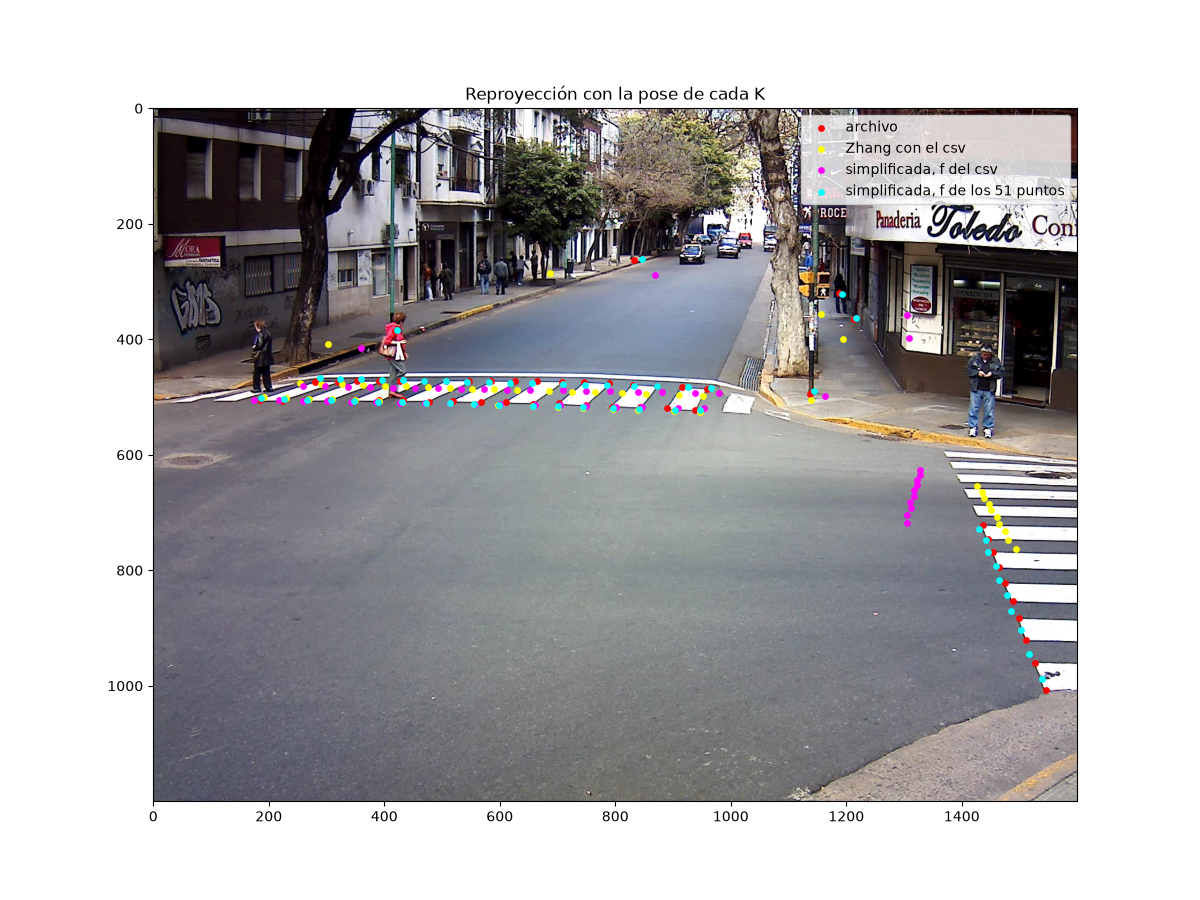

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

IDEA:

Para saber la velocidad de los vehiculos y la señora, necesitamos saber cuantos metros se movieron en el tiempo.
Osea que se relacionan 3 cosas:
- Metros recorridos: La homografia H lleva puntos de la calle (en metros) a la imagen (en pixeles) y su inversa al revés. Osea que si le damos un pixel, nos devuelve el punto de la calle correspondiente en metros (con algún error). 
- Tiempo: Cada captura tiene como nombre la hora en la que fue tomada. Con la funcion name2sec podemos pasarla a segundos (porque viene en formato hora_minuto_segundo_milisegundo) y calcular la diferencia de tiempo entre dos capturas.
- Velocidad: Es la distancia dividida por tiempo, en cada tramo entre dos marcas.


ALGUNAS CONSIDERACIONES:

El pixel que marcamos tiene que estar sobre el plano de la calle, asi que si marcamos la cabeza de la señora o el techo del auto, H^-1 los trataría como si estuvieranen el piso y los ubicaría mal. Por esto, los puntos de referencia para trackear fueron los pies de la señora y, en los vehículos, la rueda delantera del lado del conductor, ambos sobre el asfalto.

Por otro lado, la secuencia tiene unas 46 capturas y son aproximadamente unos 5 segundos, osea que el tiempo entre capturas es muy chico (de hecho no es nisiquiera constante, varían las horas de las fotos). En vez de marcar frame a frame, elegimos marcar 1 cada 5 fotos, separadas por aprox 0.5 a 0.8 s entre cada una. Esto porque al marcar los puntos para trackear a mano, un error de 2 pixeles dividido por un tiempo tan chico hace que el error en m/s incremente mucho y sea inestable. Con menos marcas, mas separadas, perdemos el detalle de como camba la velocidad pero cada valor es mucho mas confiable, y en 5 segundos no creemos que haya una variación de velocidad tan errática y rápida como para medirla aprox. 9 veces por segundo.


ANTES DE VER LAS VELOCIDADES: Estaría bueno hacer un análisis del error de la reproyección como hicimos en el b. Pero en vez de ver la diferencia en pixeles, veamos la diferencia en coordenadas del mundo real que nos devuelve H^-1:

In [13]:
def pixeles_a_mundo(H_inv, pixeles):
    """
    Lleva píxeles de la imagen a coordenadas del plano de la calle.

    Parámetros
    ----------
    H_inv : ndarray (3, 3) — inversa de la homografía calle → imagen.
    pixeles : ndarray (n, 2) — puntos (u, v) en píxeles, sobre el piso.

    Devuelve
    --------
    mundo : ndarray (n, 2) — puntos (X, Y) en metros.
    """

    #Armo los pixeles en coord homogeneas
    P = np.vstack((pixeles[:, 0], pixeles[:, 1], np.ones(pixeles.shape[0])))

    proy = alc.multiplicar(H_inv, P)

    x = proy[0] / proy[2]
    y = proy[1] / proy[2]

    return alc.transponer(np.vstack((x,y)))

def name2sec(foto):
    """
    Convierte el nombre de una captura en segundos desde las 00:00.

    Parámetros
    ----------
    foto : str — instante de la captura como "hora_minuto_segundo_milisegundo".

    Devuelve
    --------
    segundos : float — instante de la captura, en segundos.
    """
    hora,minuto,segundo,ms = foto.split("_")
    return 3600*int(hora) + 60*int(minuto) + int(segundo) + int(ms)/1000 

H_inv = alc.inversa(H)
    

In [14]:
#Chequeo de H^-1: paso los 51 píxeles a metros y los comparo con sus coordenadas reales
mundo_estimado = pixeles_a_mundo(H_inv, imgPts)
error_m = np.sqrt((mundo_estimado[:, 0] - objPts[:, 0])**2 + (mundo_estimado[:, 1] - objPts[:, 1])**2)
print(f"Error de H^-1 en la calle: promedio {np.mean(error_m):.2f} m, máximo {np.max(error_m):.2f} m")

#Cuál es el punto con más error
for i in range(error_m.shape[0]):
    if error_m[i] == np.max(error_m):
        print(f"Peor punto: (X, Y) = ({objPts[i, 0]}, {objPts[i, 1]}), error {error_m[i]:.2f} m")

Error de H^-1 en la calle: promedio 0.28 m, máximo 2.04 m
Peor punto: (X, Y) = (-6.0, 76.0), error 2.04 m


El error es bastante chico dentro de todo. El peor punto es el mas lejano, a 76mts. Al fondo, cada pixel cubre mas espacio que un pixel correspondiente a algo cercano a la cámara, por lo que es de esperar que mientras más lejos, mas error haya. El error promedio es muy bueno, de unos 28cms, por lo que la señora, que está cerca, esperamos que tenga una velocidad confiable y estable, mientras que los vehiculos pueden presentar una variación mayor, consecuencia de errores al marcar el pixel en cada imagen.

Ahora si, veamos la velocidad de cada uno:


señora : velocidad media 1.3626737365626103 m/s = 4.905625451625397 km/h
taxi : velocidad media 13.343154731416021 m/s = 48.035357033097675 km/h
camioneta : velocidad media 13.897807951443237 m/s = 50.032108625195654 km/h


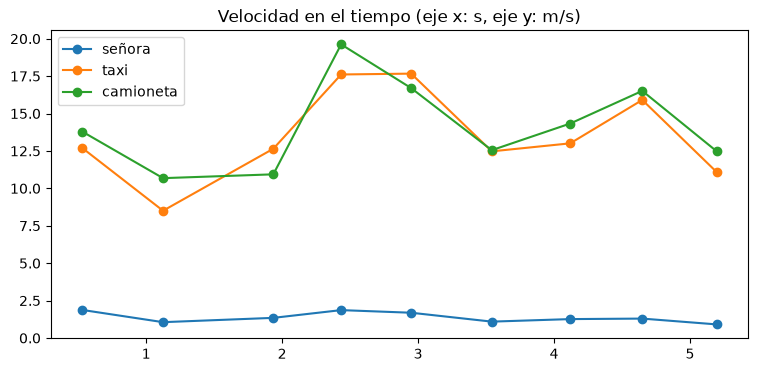

In [15]:
def calcular_velocidad(archivo_marcas, H_inv):
    """
    Calcula la velocidad de un agente a partir de sus marcas en la imagen.

    Parámetros
    ----------
    archivo_marcas : str — nombre del .csv en salguero/ (columnas captura;u;v).
    H_inv : ndarray (3, 3) — inversa de la homografía calle → imagen.

    Devuelve
    --------
    t : ndarray (n,) — tiempo de cada marca, en segundos desde la primera.
    v : ndarray (n-1,) — velocidad en cada tramo, en m/s.
    mundo : ndarray (n, 2) — posiciones (X, Y) en metros.
    """
    marcas = pd.read_csv(os.path.join("salguero", archivo_marcas), sep=";", dtype={"captura": str})
    n = marcas.shape[0]

    # Tiempo de cada captura, en segundos desde la primera
    t = np.zeros(n)
    for i in range(n):
        t[i] = name2sec(marcas["captura"][i])
    t = t - t[0]

    # Paso los píxeles a metros sobre el plano de la calle
    pixeles = np.array(marcas[["u", "v"]], dtype=float)
    mundo = pixeles_a_mundo(H_inv, pixeles)

    # Distancia recorrida entre marcas consecutivas
    dX = np.diff(mundo[:, 0])
    dY = np.diff(mundo[:, 1])
    dist = np.sqrt(dX**2 + dY**2)

    # Velocidad = distancia / tiempo entre marcas
    v = dist / np.diff(t)

    return t, v, mundo


actores = [("señora", "marcas_senora.csv"),
           ("taxi", "marcas_taxi.csv"),
           ("camioneta", "marcas_camioneta.csv")]

plt.figure(figsize=(9, 4))
for nombre, archivo in actores:
    t, v, mundo = calcular_velocidad(archivo, H_inv)
    # Velocidad media: distancia total / tiempo total (cada tramo pesa según cuánto dura)
    v_media = np.sum(v * np.diff(t)) / t[-1]
    print(nombre, ": velocidad media", v_media, "m/s =", 3.6*v_media, "km/h")
    plt.plot(t[1:], v, marker="o", label=nombre)

plt.title("Velocidad en el tiempo (eje x: s, eje y: m/s)")
plt.legend()
plt.show()

ANÁLISIS DE LOS RESULTADOS: 

Las velocidades medias:
- Señora: 1.36 m/s (unos 4.9km/h). Valor normal esperado.
- Taxi: 13.3 m/s (unos 48 km/h).
- Camioneta: 13.9 m/s (unos 50 km/h).

Las velocidades tienen sentido. 

Saltan a la vista un par de cosas:

- La variacion de la velocidad de un tramo al otro se debe en parte al error al marcar los pixeles. Queda hiper evidente porque de un tramo al otro la velocidad de los vehículos está variando entre 8.5 m/s a 19.6 m/s. Esto es porque, como dijimos, mientras mas lejos de la cámara, un pixel representa mas distancia en el mundo real, por lo que es de esperar variaciones grandes por un error de pocos pixeles. Los de la señora varían menos pero porque su velocidad es menor y estan cerca del centro de la cámara, a menor distancia, donde vimos además que había menor error en las mediciones.

- Hay un patrón extraño en las 3 curvas. Parecería que los tres frenan y aceleran en los mismos tramos. En el tramo 2, los tres frenan y en el 4 los tres aceleran. Si fuera un error de marcado, lo esperable sería que cada uno fallara distinto. Que coincidan nos hace pensar que quizas hay un error en el tiempo de la medición. Quizás la hora de las fotos no son del instante en que se tomaron si no del momento de guardarla, o quizas fueron modificados. No tenemos manera de saberlo.

A pesar de que hay ruido entre tramo y tramo, en conjunto y a la larga, se estabiliza y la velocidad media da algo coherente.

ESTO LO PODEMOS BORRAR PORQUE NO SE SI PINTA AGREGARLO, LO DEJO POR AHORA AUNQUE LO SUBA AL PR ASI LO VEN YA QUE DESPUES LO VAMOS A REVISAR

Entré en el rabbit hole de qué puede llegar a ser esto del tiempo de las capturas y chequeense este triple:
Resulta ser que todas las diferencias entre los timestamps de las fotos son multiplos de 15,6 (lo que vendria a ser 1/64s), lo cual es absurdamente específico. Resulta ser que es el minimo intervalo de tiempo por el cual actualiza la hora del sistema windows. Osea que esto sugiere que el timestamp es de la hora de guardado de la foto y no de la captura en si, osea que entre que se saca la foto y se procesa y guarda, podría haber un delay y que la hora de guardado sea incorrecta, lo cual explicaria por que las 3 curvas tinenen errores que van al unisono.

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

---